# Amazon UK Product Insights Part II

In [2]:
import pandas as pd
import numpy as np
import plotly as pt
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

amazon_raw = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
amazon = amazon_raw.copy()

### Part 1: Analyzing Best-Seller Trends Across Product Categories

Here, we are trying to **understand the relationship between product categories and their best-seller status.**

We can start by creating a contingency table between  category and isBestSeller features to see if there are categories where being a best-seller is more prevalent

In [4]:
pd.crosstab(amazon["category"], amazon["isBestSeller"])

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


This way is difficult to observe if there is any trend. Why don't we calculate the proportion of bestsellers by category and then sort them in descending order?

In [37]:
amazon["is_best_seller_01"] = amazon["isBestSeller"].map({False: 0, True: 1})
grouped = pd.DataFrame(amazon.groupby("category")["is_best_seller_01"].agg(lambda x: (x.sum() / x.count()) * 100))
grouped.sort_values("is_best_seller_01",ascending=False).head(10)

,is_best_seller_01
category,
Grocery,5.813467
Smart Home Security & Lighting,5.769231
Health & Personal Care,5.768628
Mobile Phone Accessories,4.247104
Power & Hand Tools,3.533895
"Billiard, Snooker & Pool",3.212851
Pet Supplies,3.020028
Home Brewing & Wine Making,2.845528
Mirrors,2.800000


With this, we can observe that there are indeed categories with higher best seller prevalence.

Let's now see if the best-seller distribution is independent of the product category.

In [27]:
prop = pd.crosstab(amazon["category"], amazon["isBestSeller"])

chi2, p, dof, expected = stats.chi2_contingency(prop)
print(f"chi2 = {chi2:.1f}, degrees of freedom = {dof}, p-value = {p:.1e}")
pd.DataFrame(expected, index=prop.index, columns=prop.columns).round(1)

chi2 = 36540.2, degrees of freedom = 295, p-value = 0.0e+00


isBestSeller,False,True
category,,
3D Printers,247.2,0.8
3D Printing & Scanning,4053.7,13.3
Abrasive & Finishing Products,249.2,0.8
Action Cameras,1691.5,5.5
Adapters,253.2,0.8
...,...,...
Wind Instruments,249.2,0.8
Window Treatments,238.2,0.8
Women,17714.0,58.0


A very huge chi2 value indicates a huge difference between the observed and the expected values. On the other hand, a p-value of practically 0 seems to indicate that there is significant dependence between categories and them being best sellers. Let's see the strength of this association using Cramer's V:

In [28]:
from scipy.stats.contingency import association
print(f"Cramer V: {association(prop, method="cramer")}")

Cramer V: 0.1222829439760564


As we can see, a 0.1, the Cramer's V indicates a very weak association. It exists, but is weak.

Let's quickly visualize it using a stacked bar plot:

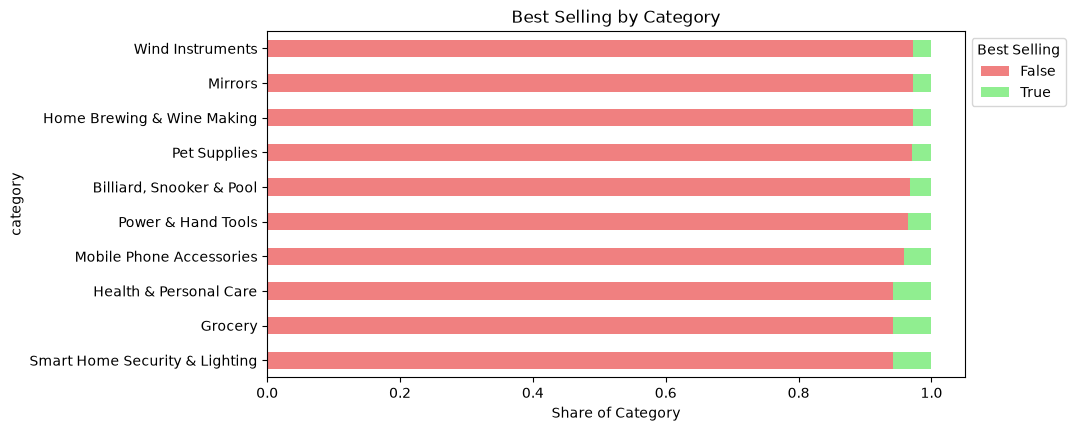

In [50]:
normal_prop = pd.crosstab(amazon["category"], amazon["isBestSeller"], normalize="index").round(3)

normal_prop.sort_values(True, ascending=False).head(10).plot(kind="barh", stacked=True, color=["lightcoral", "lightgreen"], figsize=(9, 4.5))
plt.xlabel("Share of Category")
plt.title("Best Selling by Category")
plt.legend(title="Best Selling", bbox_to_anchor=(1, 1))
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

Our next goal is to investigate **how different product categories influence product prices.**

For that, we may want to remove extreme ourliers first. Let's decide to remove prices above the third quantile plus 1.5 times the IQR or prices below the first quantile minus 1.5 times de IQR.

In [82]:
amazon.shape

(2443651, 9)

In [110]:
Q1 = amazon["price"].quantile(0.25)
Q3 = amazon["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

#This line creates a new dataframe called amazon_filtered with those records from amazon DF where:
#the prices is not below lower_bound AND not above upper_bound
amazon_filtered = amazon.loc[~(amazon["price"] < lower_bound) & ~(amazon["price"] > upper_bound)]
amazon_filtered.shape

(2115963, 9)

Now that we excluded the outlier prices, we can do some visualizations to explore the distribution of data.

Le'ts begin with a violint plot, concentrating on the top 20 categories.

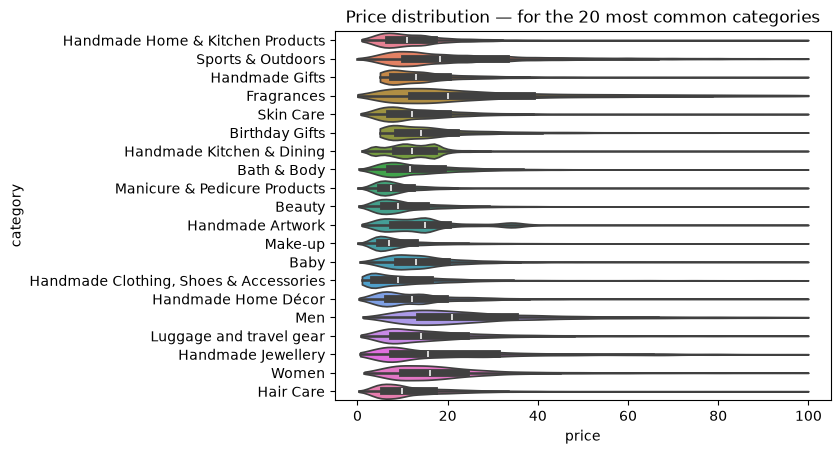

In [130]:
top20 = amazon_filtered["category"].value_counts().head(20).index
sns.violinplot(data=amazon_filtered[amazon_filtered["category"].isin(top20)], y="category", x="price",
               hue="category", legend=False, cut=0)
plt.title("Price distribution — for the 20 most common categories")
plt.show()

As we see, it seems that Men and Fragances tend to have the higer median prices. We can double check this conclusion by ordering the top 20 by median price:

In [143]:
amazon_filtered_top20_category = amazon_filtered[amazon_filtered["category"].isin(top20)]
amazon_filtered_top20_category.groupby("category")["price"].median().sort_values(ascending=False).head(5)

category
Men                   20.99
Fragrances            20.00
Sports & Outdoors     18.32
Women                 15.99
Handmade Jewellery    15.60
Name: price, dtype: float64

But what about all products without any top?

In [142]:
amazon_filtered.groupby("category")["price"].median().sort_values(ascending=False).head(5)

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

Then we see that the category with the highest median price is 3D Printers.

But don't stop at this, let's create bar chart of the top 10 categories and see what we can obtain.

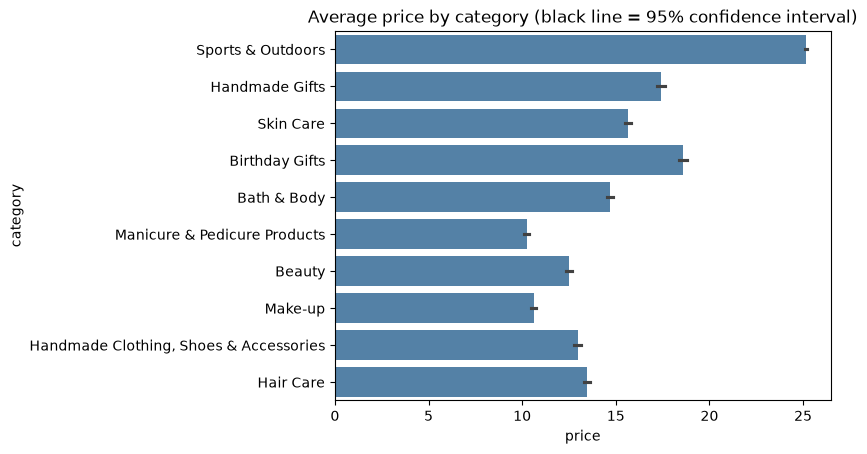

In [150]:
top10 = amazon_filtered["category"].value_counts().head(10).index
amazon_filtered_top10_category = amazon_filtered[amazon_filtered["category"].isin(top10)]

sns.barplot(data=amazon_filtered_top10_category, x="price", y="category", color="steelblue", errorbar=("ci", 95))
plt.title("Average price by category (black line = 95% confidence interval)")
plt.show()

We can see that for the top 10 categories, the ones with the highest average price are Sports & Outdoors and Birthday Gifts. We can confirm grouping and sorting by mean:

In [146]:
amazon_filtered_top10_category.groupby("category")["price"].mean().sort_values(ascending=False).head(5)

category
Sports & Outdoors    25.172065
Birthday Gifts       18.600195
Handmade Gifts       17.395112
Skin Care            15.654722
Bath & Body          14.678683
Name: price, dtype: float64

But, as we did with the violin plot, what happens if we do the same analysis but considering all categories?

In [151]:
amazon_filtered.groupby("category")["price"].mean().sort_values(ascending=False).head(5)

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

Now, we see that for entire dataset, Motherboards and Boxing Shoes are the categories with the highest average price.

Finally, why don't we use some box plots to see the distribution of product ratings based on their category? Let's go

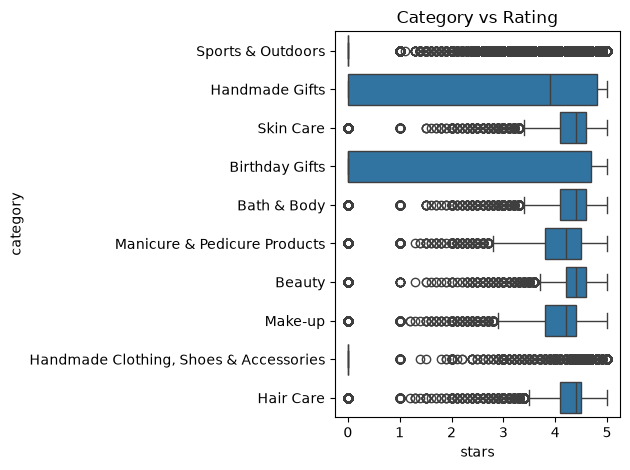

In [156]:
sns.boxplot(data=amazon_filtered_top10_category, x="stars", y="category").set_title("Category vs Rating")
plt.tight_layout()
plt.show()

It seems that there are some categories that share the same or nearly the same median rating: Bath & Body, Beauty, Hair Care... Let's confirm sorting by median:

In [157]:
amazon_filtered_top10_category.groupby("category")["stars"].median().sort_values(ascending=False).head(5)

category
Bath & Body    4.4
Beauty         4.4
Hair Care      4.4
Skin Care      4.4
Make-up        4.2
Name: stars, dtype: float64

Finally, let's see if the picture changes if we sort the median rating without pre-filtering the top 10 categories:

In [159]:
amazon_filtered.groupby("category")["stars"].median().sort_values(ascending=False).head(5)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

Now, we clearly see that there are other categories with higher median ratings, being the top category in this sense Computer Memory

### Part 3: Investigating the Interplay Between Product Prices and Ratings

For the last part, our goal will be to **analyze how product ratings (stars) correlate with product prices**.

FOr this purpose, let's obtain the spearman correlation coefficient:

In [163]:
rho, p_s = stats.spearmanr(amazon_filtered["price"], amazon_filtered["stars"])
print(f"Spearman ρ = {rho:.2f} (p = {p_s:.1e})")

Spearman ρ = -0.07 (p = 0.0e+00)


The Spearman here shows that there is a weak correlation between price and ratings.

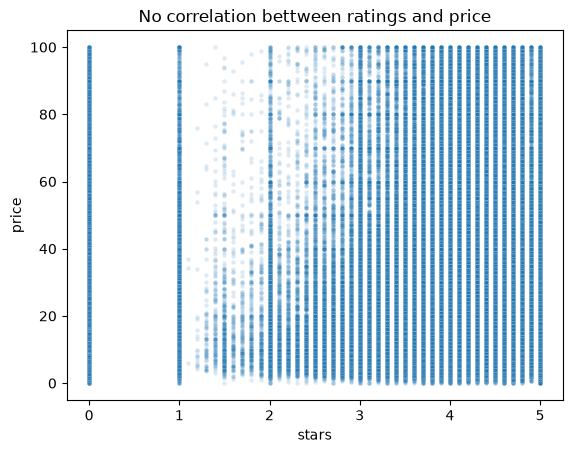

In [172]:
sns.scatterplot(data=amazon_filtered,          
                x="stars", y="price", alpha=0.15, s=10)
plt.title("No correlation bettween ratings and price")
plt.show()

As we can see, it would seem that there is very little correlation between rating and stars: prices seems to distribute more or less equally for all ratings. The only appreciation is that between 1 and 2 stars and between 2 and 3 stars, the prices tend to be a little lower (excluding the raging at exactly 2 stars that is normally distributed)

What if we analyze the correlation between all numerical variables?

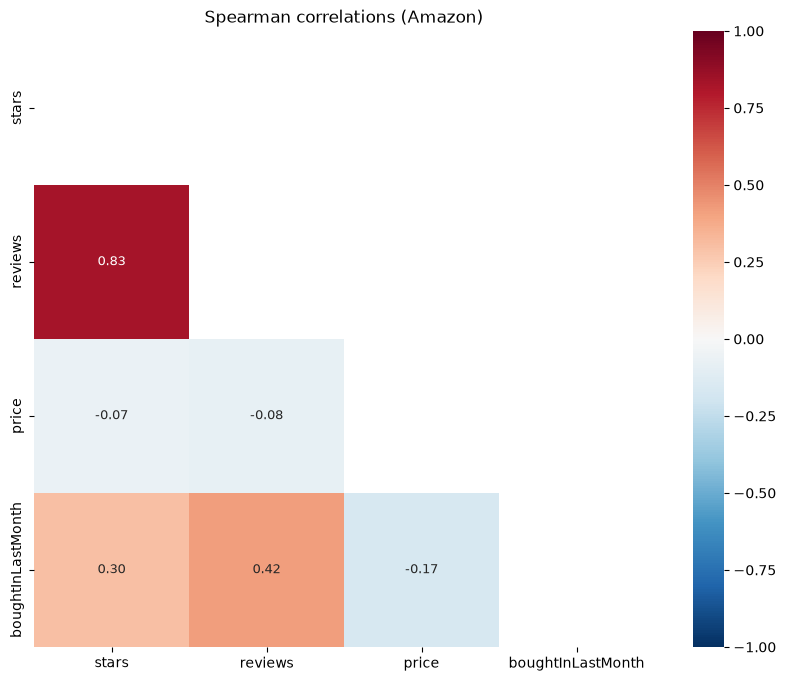

In [175]:
num_cols = ["stars", "reviews", "price", "boughtInLastMonth"]
corr = amazon_filtered[num_cols].corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))  # remove the upper triangle, as is a mirror of the lwer trinagle
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 9}, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman correlations (Amazon)")
plt.show()

We see that the amunt of reviews is strongly positively correlated with the rating. Also, the amount of reviews seems also positively correlated with the amount of items bought in last month

For our last trick, let's see if the price feature follows a normal distribution using a QQ plot.

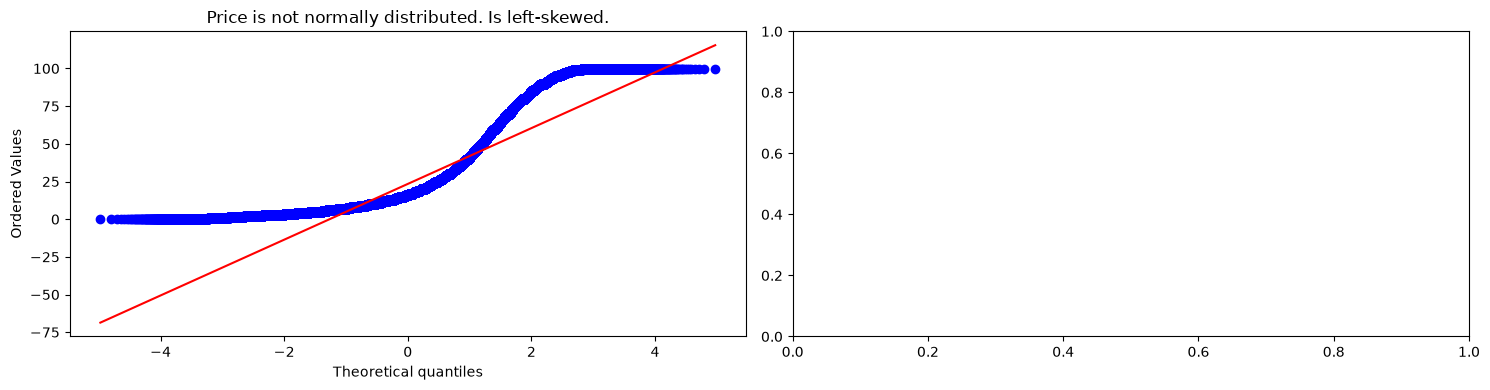

In [188]:
fig, axes = plt.subplots(1,2, figsize=(15, 4))

stats.probplot(amazon_filtered["price"], dist="norm", plot=axes[0])
axes[0].set_title("Price is not normally distributed. Is left-skewed.")

plt.tight_layout()
plt.show()

As we can see, the price feature is left skewed, is not normally distributed.